In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models

# Path on Google Drive
dataset_dir = '/content/drive/MyDrive/Primary model (deep learning)/Primary'

# Parameters
BATCH_SIZE = 32
IMG_SIZE = (128, 128)

# Custom tf.data loader to natively read and decode .jfif images
def parse_image(file_path, label):
    image = tf.io.read_file(file_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

# Gather file paths and labels manually
class_names = sorted(os.listdir(dataset_dir))
num_classes = len(class_names)
file_paths = []
labels = []
for label_idx, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_dir, class_name)
    if os.path.isdir(class_path):
        for filename in os.listdir(class_path):
            if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.gif', '.jfif')):
                file_paths.append(os.path.join(class_path, filename))
                labels.append(label_idx)

dataset_size = len(file_paths)
print(f"Custom loader found {dataset_size} files belonging to {num_classes} classes.")

# Zip and shuffle
full_dataset = tf.data.Dataset.from_tensor_slices((file_paths, labels))
full_dataset = full_dataset.shuffle(buffer_size=dataset_size, seed=123)

# Map parsing function
full_dataset = full_dataset.map(parse_image, num_parallel_calls=tf.data.AUTOTUNE)

# Split into training (80%) and validation (20%)
train_size = int(0.8 * dataset_size)
train_ds = full_dataset.take(train_size).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = full_dataset.skip(train_size).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

print(f"Dataset ready. Train size: {train_size}, Validation size: {dataset_size - train_size}")

Custom loader found 60 files belonging to 3 classes.
Dataset ready. Train size: 48, Validation size: 12


In [13]:
# Define the CNN model architecture
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

# Compile the model
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy() if num_classes > 2 else tf.keras.losses.BinaryCrossentropy()

model.compile(
    optimizer='adam',
    loss=loss_fn,
    metrics=['accuracy']
)

model.summary()

# Train the model
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,121,251 (8.09 MB)

 Trainable params: 2,121,251 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 432ms/step - accuracy: 0.2917 - loss: 1.7053 - val_accuracy: 0.5833 - val_loss: 1.1351
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 516ms/step - accuracy: 0.3333 - loss: 1.2767 - val_accuracy: 0.3333 - val_loss: 1.1155
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 563ms/step - accuracy: 0.3750 - loss: 1.1146 - val_accuracy: 0.1667 - val_loss: 1.1141
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 347ms/step - accuracy: 0.2917 - loss: 1.0989 - val_accuracy: 0.4167 - val_loss: 1.0870
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - accuracy: 0.3958 - loss: 1.0883 - val_accuracy: 0.2500 - val_loss: 1.0936
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 301ms/step - accuracy: 0.3333 - loss: 1.0929 - val_accuracy: 0.3333 - val_loss: 1.1337
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 289ms/step - accuracy: 0.4375 - loss: 1.0975 - val_accuracy: 0.3333 - val_loss: 1.0856
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 284ms/step - accuracy: 0.3542 - loss: 1.0876 - val_accuracy: 0.3333 - val_loss:

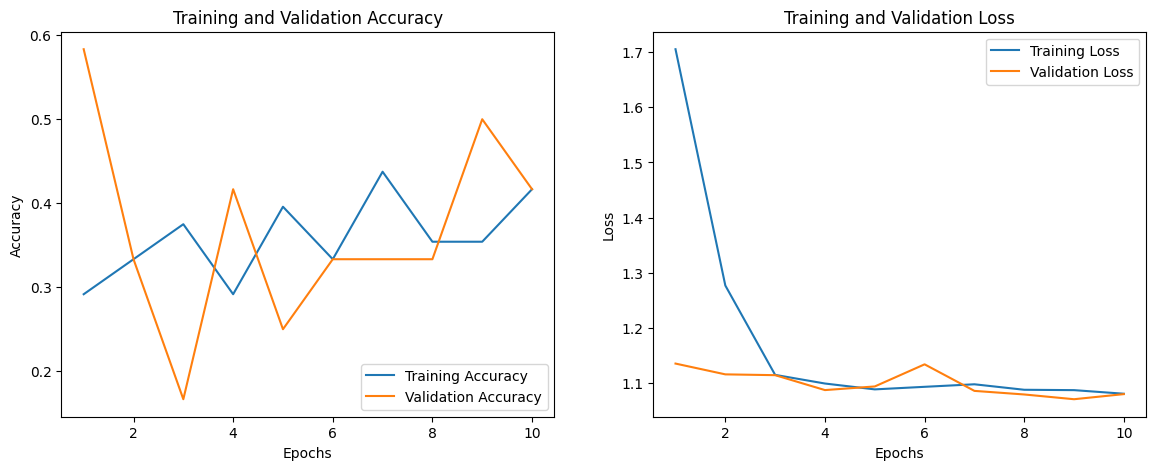

In [14]:
import matplotlib.pyplot as plt

# Extract training history metrics
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Plot Training and Validation Accuracy & Loss
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

In [15]:
# Evaluate the model's performance on the validation dataset
eval_loss, eval_accuracy = model.evaluate(val_ds)
print(f"\nValidation (Test) Accuracy: {eval_accuracy * 100:.2f}%")
print(f"Validation (Test) Loss: {eval_loss:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.6667 - loss: 1.0616

Validation (Test) Accuracy: 66.67%
Validation (Test) Loss: 1.0616


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step


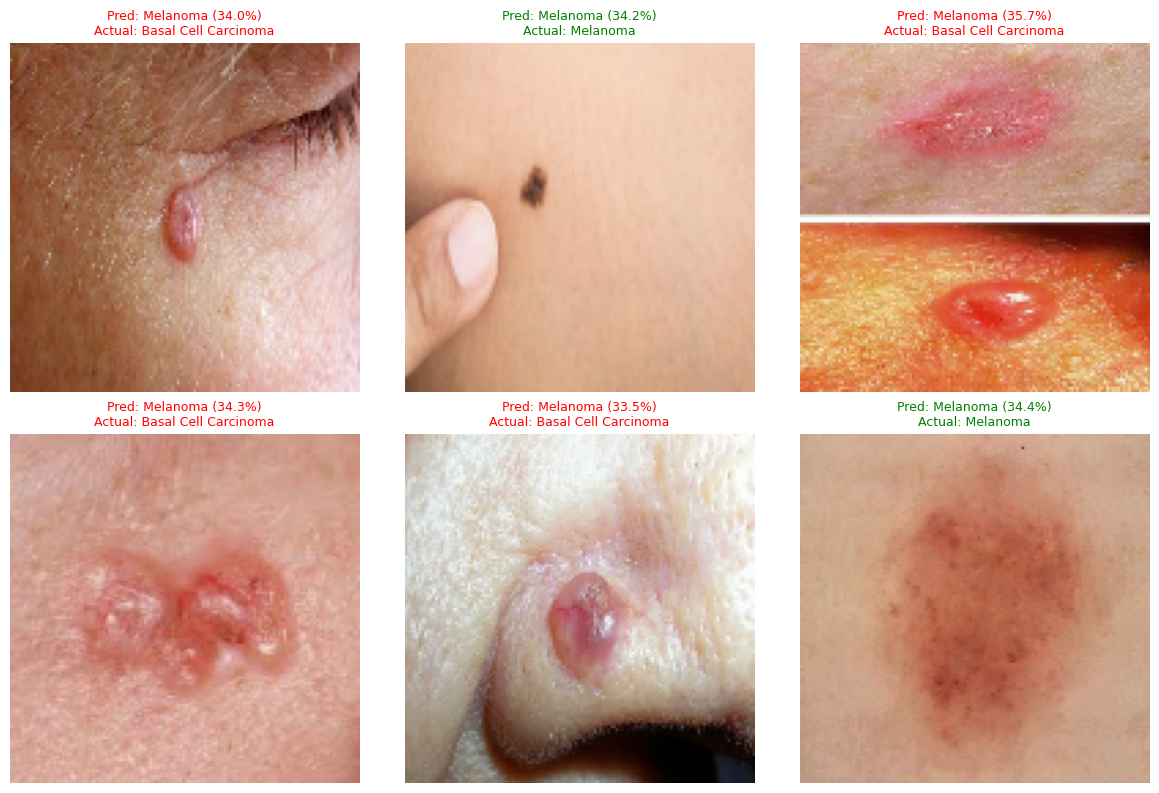

In [16]:
import numpy as np

# Take one batch from the validation dataset and show predictions
for images, labels in val_ds.take(1):
    predictions = model.predict(images)

    plt.figure(figsize=(12, 8))
    # Show up to 6 sample predictions
    for i in range(min(6, len(images))):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        predicted_label = np.argmax(predictions[i])
        actual_label = int(labels[i])
        confidence = predictions[i][predicted_label] * 100

        title_color = "green" if predicted_label == actual_label else "red"
        plt.title(f"Pred: {class_names[predicted_label]} ({confidence:.1f}%)\nActual: {class_names[actual_label]}", color=title_color, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()